# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Ricerra, Myke Lawrence F.
- _Student No._: 2024-07203
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="figures/8.png" alt="Plot of the Given Functions and their First Derivative" width=80%> 
<i>Figure 1: Plot of the Given Functions and their First Derivative</i>

### Report discussion

If the golden ratio isn't used to perform the golden section search, then it is no longer the golden section search. Kidding aside, we use the golden ratio primarily for its geometric symmetry. Its proportions remain constant throughout every iteration, regardless of whether we eliminate the sub-interval from $x_0 \to x_2$ or from $x_3 \to x_1$. As a direct consequence of this, one interior point from the previous iteration is automatically preserved and recycled, meaning we only need to compute a single new function value per step. While using any other ratio would still technically work, the efficiency that the golden ratio guarantees completely vanish, doubling the required computations per iteration and slowing down convergence.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4 = (((x-9)x + 25)x - 24)x + 4
$$
$$
\Rightarrow\phi'(x) = 4x^3 - 27x^2 + 50x - 24 = ((4x - 27)x + 50)x - 24
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8 = (x-2)^2 (e^x - x^3 - 2)
$$
$$
\Rightarrow f'(x) = (x-2)(xe^x - 5x^3 +6x^2 - 4)
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [2]:
def phi(x):
    return 4 + x*(-24 + x*(25 + x*(-9 + x)))

def f(x):
    return (x-2) ** 2 * (np.exp(x) - x**3 - 2)

def dphi(x):
    return -24 + x*(50 + x*(-27 + 4*x))

def df(x):
    return (x-2) * (x*np.exp(x) - 5*(x**3) + 6*(x**2) - 4)

In [3]:
#Finding the extremas/critical points using secant method

def secant(f, x0, x1, kmax=100, tol=1e-323, text=False):
  past_k = []
  past_x = []

  for k in range(1, kmax):
    f0 = f(x0)
    f1 = f(x1)

    if f1 - f0 == 0 or np.isnan(f1 - f0) or np.isinf(f1 - f0):
      print("Division by zero or invalid denominator. Stopping.")
      return None, None, None

    x2 = x1 - f1 * (x1 - x0) / (f1 - f0)

    if np.isnan(x2) or np.isinf(x2):
      print("Encountered NaN or Infinity. Stopping.")
      return None, None, None

    error = np.abs(x2 - x1)

    rowf = "{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}"
    if text: print(rowf.format(k, x2, error, np.abs(f(x2))))
    past_k.append(k)
    past_x.append(x2)

    if error < tol:
      break

    x0 = x1
    x1 = x2
  else:
    print("Maximum iterations reached without convergence.")
    x2 = None
  return x2, np.array(past_k), np.array(past_x)

print("Finding Zeros of First Derivative using Secant Method \nCritical points of phi(x)")
for x0, x1 in ((0.5, 0.95), (1.95, 2.04), (3.9, 4.05)):
  root, past_k, past_x = secant(dphi, x0, x1, text=False)
  print(root)

print("\n""Critical points of f(x)")
for x0, x1 in ((-0.9, -0.5), (1.95, 2.04), (4, 4.2)):
  root, past_k, past_x = secant(df, x0, x1, text=False)
  print(root)

Finding Zeros of First Derivative using Secant Method 
Critical points of phi(x)
0.7500000000000001
2.000000000000001
3.9999999999999996

Critical points of f(x)
-0.679862007752152
2.0
4.103324864295675


In [4]:
gr = 0.5*(1+np.sqrt(5))

def gss(g, x0, x1, le, kmax=100, tol=1e-12, text=False):
    for k in range(1, kmax):
        x2 = x0 + (x1 - x0)/(gr + 1)
        x3 = x0 + (x1 - x0)/gr

        if le == "min":
            if g(x2) < g(x3):
                x1 = x3
            else:
                x0 = x2
        elif le == "max":
            if g(x2) > g(x3):
                x1 = x3
            else:
                x0 = x2
        
        crit = (x0+x1)/2
        xdiff = np.abs(x1-x0)
        rowf = "{0:2d} {1:1.16f} {2:1.16f} {3:1.16f} {4}"
        if text: print(rowf.format(k, crit, xdiff, g(crit), local_ext))

        if xdiff < tol:
            break
    else: crit = None
    return crit

phicp = []
fcp = []

print("Golden Section Search \nCritical points of phi(x)")
for x0, x1, le in ((0.5, 0.95, "min"), (1.95, 2.1, "max"), (3, 5, "min")):
    local_ext = gss(phi, x0, x1, le)
    phicp.append(local_ext)
    print(local_ext)
print("\n""Critical points of f(x)")
for x0, x1, le in ((-1, 0, "min"), (0, 3, "max"), (3, 5, "min")):
    local_ext = gss(f, x0, x1, le)
    fcp.append(local_ext)
    print(local_ext)

Golden Section Search 
Critical points of phi(x)
0.7500000062832572
1.999999980895064
4.0000000340656925

Critical points of f(x)
-0.6798620043803727
2.0000000000001443
4.10332486982715


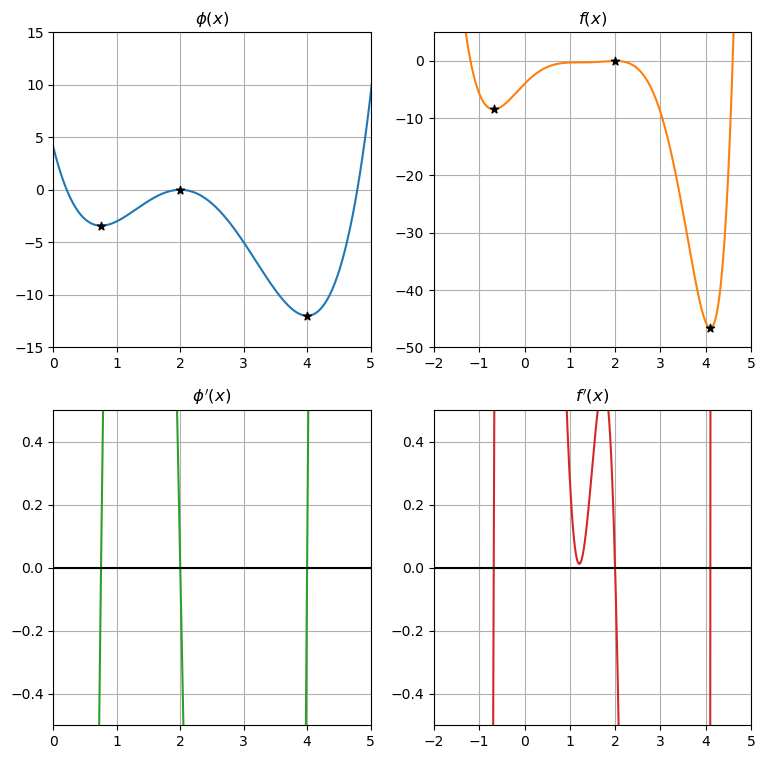

In [5]:
x = np.linspace(-10, 10, 1000)

fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].set_title(r'$\phi(x)$')
axs[0, 0].set_xlim(0, 5)
axs[0, 0].set_ylim(-15, 15)
for i in phicp:
    axs[0, 0].scatter(i, phi(i), color="black", marker="*", zorder = 3)
axs[0, 0].plot(x, phi(x))
axs[0, 0].grid(True)
axs[0, 1].plot(x, f(x), 'tab:orange')
axs[0, 1].set_title(r'$f(x)$')
axs[0, 1].set_xlim(-2, 5)
axs[0, 1].set_ylim(-50, 5)
for i in fcp:
    axs[0, 1].scatter(i, f(i), color="black", marker="*", zorder = 3)
axs[0, 1].grid(True)
axs[1, 0].plot(x, dphi(x), 'tab:green')
axs[1, 0].set_title(r"$\phi'(x)$")
axs[1, 0].set_xlim(0, 5)
axs[1, 0].set_ylim(-.5, .5)
axs[1, 0].axhline(y=0, color="black")
axs[1, 0].grid(True)
axs[1, 1].plot(x, df(x), 'tab:red')
axs[1, 1].set_title(r"$f'(x)$")
axs[1, 1].set_xlim(-2, 5)
axs[1, 1].set_ylim(-.5, .5)
axs[1, 1].axhline(y=0, color="black")
axs[1, 1].grid(True)
fig.show()

#### Problem 1 code summary

I first found the analytic first derivative of the function, then used the secant method to find the zeros (which correspond to the local extrema) for verification using the golden section search. I then created the golden section search function, which also depends on the type of local extremum we are finding (based on the graph of the original function).

---